# Forecast Benchmark

Benchmarks the three baseline `chainsim.ai.forecaster.Forecaster` implementations
— `NaiveForecaster`, `MovingAverageForecaster`, `ExponentialSmoothingForecaster`
— on synthetic-but-realistic weekly demand data (trend + seasonality + noise,
in the shape of M5/WSTS-style retail data), via a rolling-origin backtest.

The intended real-world workflow: load a CSV of historical demand, wrap it
with `chainsim.core.demand.EmpiricalDemand` to drive the simulator, and use
the same array to benchmark forecasters here — both consume the identical
data. We generate the array synthetically below so this notebook runs with
no external data file.


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from chainsim.ai.forecaster import (
    ExponentialSmoothingForecaster,
    Forecaster,
    MovingAverageForecaster,
    NaiveForecaster,
    forecast_accuracy,
)
from chainsim.core.demand import EmpiricalDemand

SEED = 0

## Synthetic demand data

2 years of weekly demand: a slow upward trend, a 52-week seasonal cycle, and
Poisson-like noise — then wrapped in `EmpiricalDemand`, the class you'd use
to drive `SimulationEngine` from a real historical CSV.


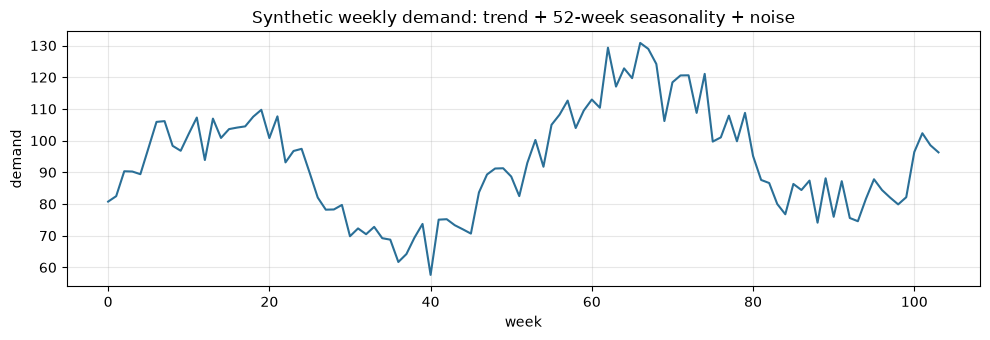

In [2]:
N_WEEKS = 104
t = np.arange(N_WEEKS)
rng = np.random.default_rng(SEED)

base, trend_per_week, amplitude, period = 80.0, 0.25, 25.0, 52
signal = base + trend_per_week * t + amplitude * np.sin(2 * np.pi * t / period)
noise = rng.normal(0.0, 6.0, size=N_WEEKS)
demand_series = np.clip(signal + noise, 0, None)

# The intended usage: wrap the historical array so it can drive a SimulationEngine
# exactly like any other DemandGenerator.
empirical_demand = EmpiricalDemand(demand_series)

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(t, demand_series, color="#2a6f97")
ax.set_xlabel("week")
ax.set_ylabel("demand")
ax.set_title("Synthetic weekly demand: trend + 52-week seasonality + noise")
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

## Rolling-origin backtest

At each origin `t`, each forecaster is fit only on `demand_series[:t]` (what
would actually have been known at that point) and forecasts the next
`HORIZON` weeks; we score against what actually happened. This is repeated
at every origin from `MIN_TRAIN` onward and the errors averaged — a single
fit/predict would only tell you about one moment in the series.


In [3]:
HORIZON = 4
MIN_TRAIN = 20


def rolling_backtest(
    forecaster: Forecaster, series: np.ndarray, horizon: int, min_train: int
) -> pd.DataFrame:
    rows = []
    for origin in range(min_train, len(series) - horizon):
        forecaster.fit(series[:origin])
        predicted = forecaster.predict(horizon)
        actual = series[origin : origin + horizon]
        rows.append({"origin": origin, **forecast_accuracy(actual, predicted)})
    return pd.DataFrame(rows)


forecasters = {
    "Naive": NaiveForecaster(),
    "MovingAverage(window=8)": MovingAverageForecaster(window=8),
    "ExponentialSmoothing(alpha=0.3)": ExponentialSmoothingForecaster(alpha=0.3),
}

backtests = {
    name: rolling_backtest(f, demand_series, HORIZON, MIN_TRAIN) for name, f in forecasters.items()
}

summary = pd.DataFrame(
    {name: df[["mae", "rmse", "mape"]].mean() for name, df in backtests.items()}
).T
summary.index.name = "forecaster"
print(
    f"Mean accuracy over {len(next(iter(backtests.values())))} backtest origins "
    f"({HORIZON}-week-ahead forecasts):\n"
)
print(summary.round(3).to_string())

Mean accuracy over 80 backtest origins (4-week-ahead forecasts):

                                    mae    rmse    mape
forecaster                                             
Naive                             7.987   9.117   8.855
MovingAverage(window=8)          11.126  12.245  12.512
ExponentialSmoothing(alpha=0.3)   9.401  10.530  10.552


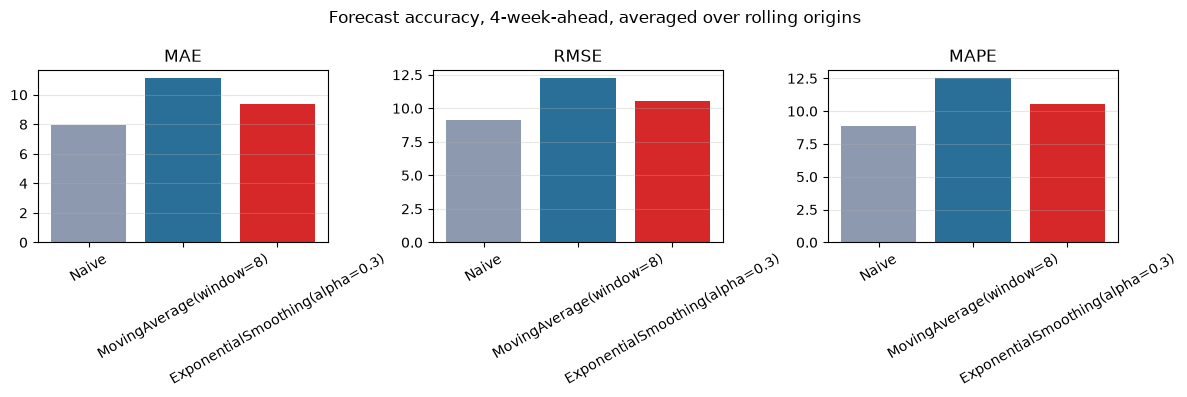

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, metric in zip(axes, ["mae", "rmse", "mape"], strict=True):
    ax.bar(summary.index, summary[metric], color=["#8d99ae", "#2a6f97", "#d62828"])
    ax.set_title(metric.upper())
    ax.tick_params(axis="x", rotation=30)
    ax.grid(axis="y", alpha=0.3)
fig.suptitle(f"Forecast accuracy, {HORIZON}-week-ahead, averaged over rolling origins")
fig.tight_layout()
fig.savefig("04_forecast_accuracy.png", dpi=150)
plt.show()

## A sample forecast, visually

One origin near the end of the series: each forecaster's 4-week-ahead
prediction (flat, since none of these baselines model trend/seasonality)
against what demand actually did.


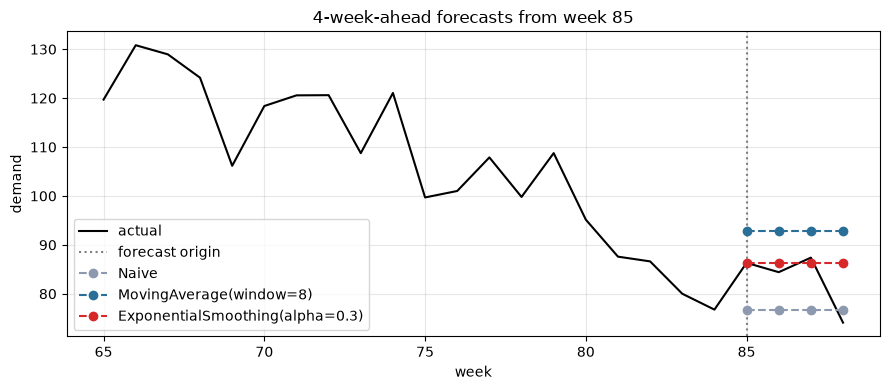

In [5]:
sample_origin = N_WEEKS - HORIZON - 15
history = demand_series[:sample_origin]
actual_future = demand_series[sample_origin : sample_origin + HORIZON]

fig, ax = plt.subplots(figsize=(9, 4))
context = 20
ax.plot(
    range(sample_origin - context, sample_origin + HORIZON),
    demand_series[sample_origin - context : sample_origin + HORIZON],
    color="black",
    label="actual",
)
ax.axvline(sample_origin, color="gray", linestyle=":", label="forecast origin")
colors = {
    "Naive": "#8d99ae",
    "MovingAverage(window=8)": "#2a6f97",
    "ExponentialSmoothing(alpha=0.3)": "#d62828",
}
for name, f in forecasters.items():
    f.fit(history)
    pred = f.predict(HORIZON)
    weeks = range(sample_origin, sample_origin + HORIZON)
    ax.plot(weeks, pred, "--o", color=colors[name], label=name)
ax.set_xlabel("week")
ax.set_ylabel("demand")
ax.set_title(f"{HORIZON}-week-ahead forecasts from week {sample_origin}")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

## Takeaways

- All three baselines forecast a *flat* line — none of them model trend or
  seasonality explicitly — so on data with a real 52-week cycle and upward
  drift, expect real forecast error from all of them; the comparison above
  is about which is *least* wrong, not which is right.
- Worth being upfront about the actual result: **`NaiveForecaster` wins**
  here, beating both smoothing methods on every metric. That's not a bug in
  `MovingAverageForecaster`/`ExponentialSmoothingForecaster` — it's a real,
  well-known forecasting phenomenon. This series has a steady local trend;
  averaging over a window (or smoothing across many past observations)
  pulls the forecast back toward a *stale* level, while naive-repeat stays
  at the most current point and rides the trend for a few weeks — exactly
  what a short (`HORIZON=4`) horizon rewards. Averaging's real advantage —
  filtering out noise — matters more at longer horizons or on flatter
  series; try raising `HORIZON` or dropping the trend/noise above and
  re-running to see the ranking flip.
- Same lesson as `examples/02_custom_policy.py`: a method that sounds more
  sophisticated (smoothing/adapting vs. a flat repeat) isn't automatically
  better for a given series and horizon — that's exactly what a backtest is
  for, rather than assuming it.
- This is exactly the seam `chainsim.ai.forecaster.Forecaster` is meant for:
  wrap a real model (Prophet, LightGBM, a foundation model like
  Chronos/TimesFM) behind the same `.fit(history)` / `.predict(horizon)`
  interface and it drops into this same backtest unchanged.
